In [15]:
import torch
from GAN.src.model import build_res_unet, MainModel
from CNN.src.model import build_colorization_model
from src.evaluate import avg_deltaE, mean_chroma, mse
from src.visualize import visualize
from tensorflow.keras.utils import disable_interactive_logging
from prettytable import PrettyTable
from GAN.src.get_checkpoints import get_checkpoints

In [16]:
get_checkpoints()

ResNet backbone already available
base model already available
finetuned model already available


In [17]:
disable_interactive_logging()

In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load models

In [10]:
# CNN
# Define image size
img_size = 256

# Create the model
cnn = build_colorization_model(input_shape=(img_size, img_size, 1))

# Load weights from the .h5 file
cnn.load_weights("CNN/checkpoints/colorization-faces-unet-0.009.h5")

In [11]:
# cGANs
# load generators
net_G1 = build_res_unet(n_input=1, n_output=2, size=256)
net_G1.load_state_dict(torch.load("GAN/src/checkpoints/res18-unet.pt", map_location=device))

net_G2 = build_res_unet(n_input=1, n_output=2, size=256)
net_G2.load_state_dict(torch.load("GAN/src/checkpoints/res18-unet.pt", map_location=device))

<All keys matched successfully>

In [12]:
# base model
gan1 = MainModel(net_G = net_G1)
gan1.load_state_dict(torch.load("GAN/src/checkpoints/final_model_weights.pt", map_location=device))

model initialized with norm initialization


<All keys matched successfully>

In [13]:
# finetuned model
gan2 = MainModel(net_G = net_G2)
gan2.load_state_dict(torch.load("GAN/src/checkpoints/fine_tuned_faces.pt", map_location=device))

model initialized with norm initialization


<All keys matched successfully>

# Visualizations

KeyboardInterrupt: 

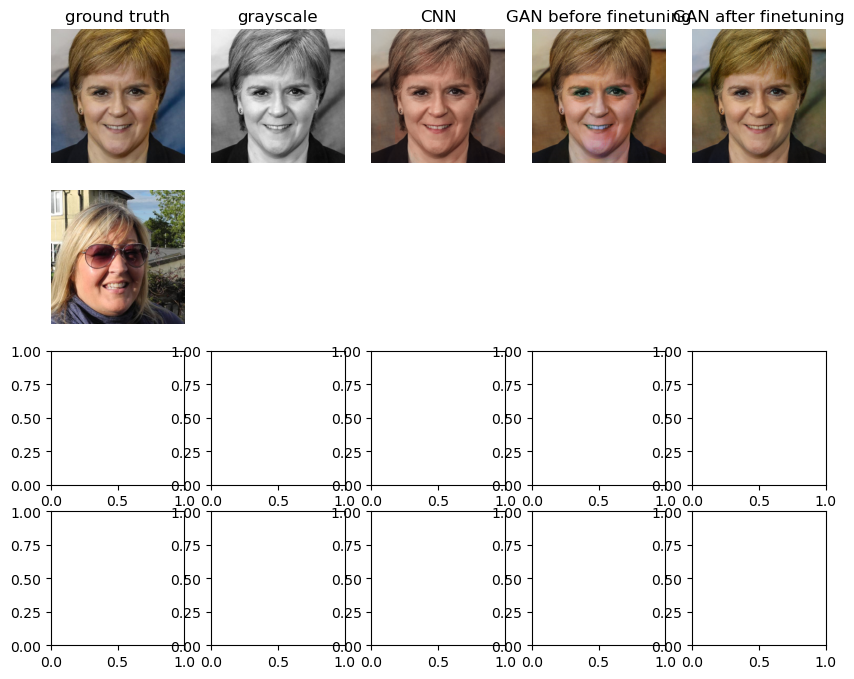

In [14]:
visualize(cnn,gan1,gan2,"data/faces_val", seed = 10)

# Evaluation

In [12]:
# number of images to be evaluated
val_path = "data/faces_val"
num_images = 10
seed = 44

In [ ]:
# CIEDE2000 Delta E score
cnn_deltae = avg_deltaE(cnn, val_path = val_path, model_type="CNN", seed = seed, size = num_images)
gan1_deltae = avg_deltaE(gan1, val_path = val_path, model_type="GAN", seed = seed, size = num_images)
gan2_deltae = avg_deltaE(gan2, val_path = val_path, model_type="GAN", seed = seed, size = num_images)

evaluating CNN:   0%|          | 0/10 [00:00<?, ?it/s]

evaluating GAN:   0%|          | 0/10 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [33]:
# mean average chroma
cnn_chroma = mean_chroma(cnn, val_path = val_path, model_type="CNN", seed = seed, size = num_images)
gan1_chroma = mean_chroma(gan1, val_path = val_path, model_type="GAN", seed = seed, size = num_images)
gan2_chroma = mean_chroma(gan2, val_path = val_path, model_type="GAN", seed = seed, size = num_images)

evaluating CNN:   0%|          | 0/10 [00:00<?, ?it/s]

evaluating GAN:   0%|          | 0/10 [00:00<?, ?it/s]

evaluating GAN:   0%|          | 0/10 [00:00<?, ?it/s]

In [34]:
# mean squared error
cnn_mse = mse(cnn, val_path = val_path, model_type="CNN", seed = seed, size = num_images)
gan1_mse = mse(gan1, val_path = val_path, model_type="GAN", seed = seed, size = num_images)
gan2_mse = mse(gan2, val_path = val_path, model_type="GAN", seed = seed, size = num_images)

evaluating CNN:   0%|          | 0/10 [00:00<?, ?it/s]

evaluating GAN:   0%|          | 0/10 [00:00<?, ?it/s]

evaluating GAN:   0%|          | 0/10 [00:00<?, ?it/s]

In [35]:
evals = PrettyTable()
evals.field_names = ["metric", "CNN", "base GAN", "finetuned GAN"]
evals.add_row(["CIDE 2000 Delta E", round(cnn_deltae,3), round(gan1_deltae,3), round(gan2_deltae,3)])
evals.add_row(["mean average chroma", round(cnn_chroma, 3), round(gan1_chroma, 3), round(gan2_chroma,3)])
evals.add_row(["MSE", round(cnn_mse, 3), round(gan1_mse,3), round(gan2_mse,3)])
print(evals)

+---------------------+--------+----------+---------------+
|        metric       |  CNN   | base GAN | finetuned GAN |
+---------------------+--------+----------+---------------+
|  CIDE 2000 Delta E  | 8.165  |  9.989   |     7.654     |
| mean average chroma | 40.689 |  41.25   |     44.534    |
|         MSE         | 57.719 |  64.126  |     50.412    |
+---------------------+--------+----------+---------------+
